# Single-Stock Risk Report (template)

Parameterized with [papermill](https://papermill.readthedocs.io): the next cell is tagged `parameters`, so `03_run_all_stocks.py` can inject `ticker`, `start_date`, `end_date` and `db_path`. Data: the `ohlc_hw_cleaned` table written by `01_data_cleaning.ipynb`.

Conventions: returns and drawdown use the **adjusted close**; volatility, Sharpe and the daily statistics use **daily log returns**; fractions are kept in calculations and formatted as percentages only for display.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy of the course database

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [3]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

TRADING_DAYS = 252
RISK_FREE_RATE = 0.02
VOL_WINDOW = 20
MA_WINDOW = 50
MIN_PRICES = VOL_WINDOW + 1   # 20 returns need 21 prices
COLORS = {"up": "#2e7d32", "down": "#c62828", "neutral": "#9e9e9e", "line": "#1f3b73", "accent": "#f9a825"}

## Data loading and validation

In [4]:
def load_prices(db_path: str, ticker: str, start_date: str, end_date: str) -> pd.DataFrame:
    """Load cleaned daily prices of one ticker between two ISO dates (inclusive), sorted by date.

    Raises ValueError for unknown tickers, inverted dates, or too little history for the 20-day metrics.
    """
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError(f"start_date {start_date} is after end_date {end_date}")
    with sqlite3.connect(db_path) as con:
        known = con.execute("SELECT 1 FROM ohlc_hw_cleaned WHERE ticker = ? LIMIT 1", (ticker,)).fetchone()
        if known is None:
            raise ValueError(f"Unknown ticker {ticker!r} in ohlc_hw_cleaned")
        df = pd.read_sql_query(
            "SELECT ts, open, high, low, close, adj_close, volume FROM ohlc_hw_cleaned "
            "WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts",
            con, params=(ticker, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")))
    df["ts"] = pd.to_datetime(df["ts"])
    df = df.set_index("ts")
    if len(df) < MIN_PRICES:
        raise ValueError(f"{ticker}: only {len(df)} prices between {start_date} and {end_date}; "
                         f"at least {MIN_PRICES} are needed for {VOL_WINDOW} daily returns")
    return df


def market_dates_in_window(db_path: str, start_date: str, end_date: str) -> tuple[pd.Timestamp, pd.Timestamp]:
    """First and last dates on which any ticker has a price inside the window (its actual market days)."""
    with sqlite3.connect(db_path) as con:
        first, last = con.execute(
            "SELECT MIN(ts), MAX(ts) FROM ohlc_hw_cleaned WHERE ts BETWEEN ? AND ?",
            (pd.Timestamp(start_date).strftime("%Y-%m-%d"), pd.Timestamp(end_date).strftime("%Y-%m-%d"))).fetchone()
    return pd.Timestamp(first), pd.Timestamp(last)

In [5]:
prices = load_prices(db_path, ticker, start_date, end_date)
first_obs, last_obs = prices.index[0].date(), prices.index[-1].date()
market_first, market_last = market_dates_in_window(db_path, start_date, end_date)
print(f"{ticker} from {start_date} to {end_date}: {len(prices)} trading days")
print(f"Actual coverage: first observation {first_obs}, last observation {last_obs}")
if prices.index[-1] < market_last:
    print(f"Note: {ticker}'s data ends on {last_obs}, while the database has prices up to {market_last.date()} "
          "in this window. Nothing is extrapolated, so this report covers a shorter period than the window.")
if prices.index[0] > market_first:
    print(f"Note: {ticker}'s data starts on {first_obs}, after the window's first market day "
          f"({market_first.date()}), so this report covers a shorter period than the window.")
pd.concat([prices.head(3), prices.tail(3)])

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: first observation 2024-06-03, last observation 2024-11-29


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


## Risk metrics

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns ln(P_t / P_{t-1}); the first value is NaN."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = VOL_WINDOW) -> pd.Series:
    """Annualized rolling volatility: rolling std of daily log returns x sqrt(252).

    The first `window` values stay NaN (warm-up); they are never filled with zero.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Per-date drawdown from the running peak: (price - running max) / running max.

    The name is kept from the assignment; the result is the drawdown series (it recovers). The maximum
    drawdown of the period is its minimum, `calculate_max_drawdown(p).min()`.
    """
    running_max = prices.cummax()
    return (prices - running_max) / running_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = RISK_FREE_RATE) -> float:
    """Annualized Sharpe ratio (course approximation): (mean * 252 - rf) / (std * sqrt(252)).

    Returns NaN when there are fewer than two returns or the volatility is zero.
    """
    r = returns.dropna()
    if len(r) < 2:
        return float("nan")
    std = r.std()
    if not np.isfinite(std) or std == 0:
        return float("nan")
    return (r.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))

In [7]:
adj = prices["adj_close"]
log_returns = calculate_returns(adj)
rolling_vol = calculate_volatility(log_returns)
drawdown = calculate_max_drawdown(adj)
moving_avg = adj.rolling(MA_WINDOW).mean()        # NaN until 50 prices exist
sharpe = calculate_sharpe_ratio(log_returns)
mean_vol = rolling_vol.mean()

pd.DataFrame({"adj_close": adj, "log_return": log_returns, "rolling_vol_20d": rolling_vol,
              "drawdown": drawdown, "ma_50d": moving_avg}).tail()

,adj_close,log_return,rolling_vol_20d,drawdown,ma_50d
ts,,,,,
2024-11-22,222.97,0.002560,0.241515,-0.044769,218.0336
2024-11-25,226.13,0.014073,0.241623,-0.031231,218.2470
2024-11-26,228.83,0.011869,0.236457,-0.019664,218.5744
2024-11-27,226.92,-0.008382,0.212190,-0.027847,218.8476
2024-11-29,227.41,0.002157,0.212125,-0.025748,219.1514


## Visual report

In [8]:
def plot_price_by_volatility(ax, adj: pd.Series, vol: pd.Series, threshold: float, ma: pd.Series) -> None:
    """Price line colored by volatility regime (red above the mean rolling vol, green at or below, gray in warm-up)."""
    x = np.arange(len(adj))
    points = np.column_stack([x, adj.to_numpy()])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    seg_vol = vol.to_numpy()[1:]
    colors = np.where(np.isnan(seg_vol), COLORS["neutral"],
                      np.where(seg_vol > threshold, COLORS["down"], COLORS["up"]))
    ax.add_collection(LineCollection(segments, colors=colors, linewidths=1.8))
    if ma.notna().any():
        ax.plot(x, ma.to_numpy(), color=COLORS["line"], linewidth=1.4, linestyle="--", label=f"{MA_WINDOW}-day MA")
    else:
        ax.text(0.02, 0.04, f"{MA_WINDOW}-day MA unavailable: only {len(adj)} prices", transform=ax.transAxes, fontsize=9)
    ax.set_xlim(0, max(len(adj) - 1, 1))
    ax.set_ylim(np.nanmin(adj) * 0.97, np.nanmax(adj) * 1.03)
    legend = [Line2D([0], [0], color=COLORS["down"], lw=2, label="vol above mean"),
              Line2D([0], [0], color=COLORS["up"], lw=2, label="vol at or below mean"),
              Line2D([0], [0], color=COLORS["neutral"], lw=2, label="vol warm-up")]
    if ma.notna().any():
        legend.append(Line2D([0], [0], color=COLORS["line"], lw=1.4, ls="--", label=f"{MA_WINDOW}-day MA"))
    ax.legend(handles=legend, loc="best", fontsize=9)


def set_date_ticks(ax, index: pd.DatetimeIndex, n: int = 6) -> None:
    """Show dates on an axis whose x values are positions 0..len-1."""
    pos = np.linspace(0, len(index) - 1, min(n, len(index))).astype(int)
    ax.set_xticks(pos)
    ax.set_xticklabels([index[i].strftime("%Y-%m-%d") for i in pos], rotation=30, ha="right")

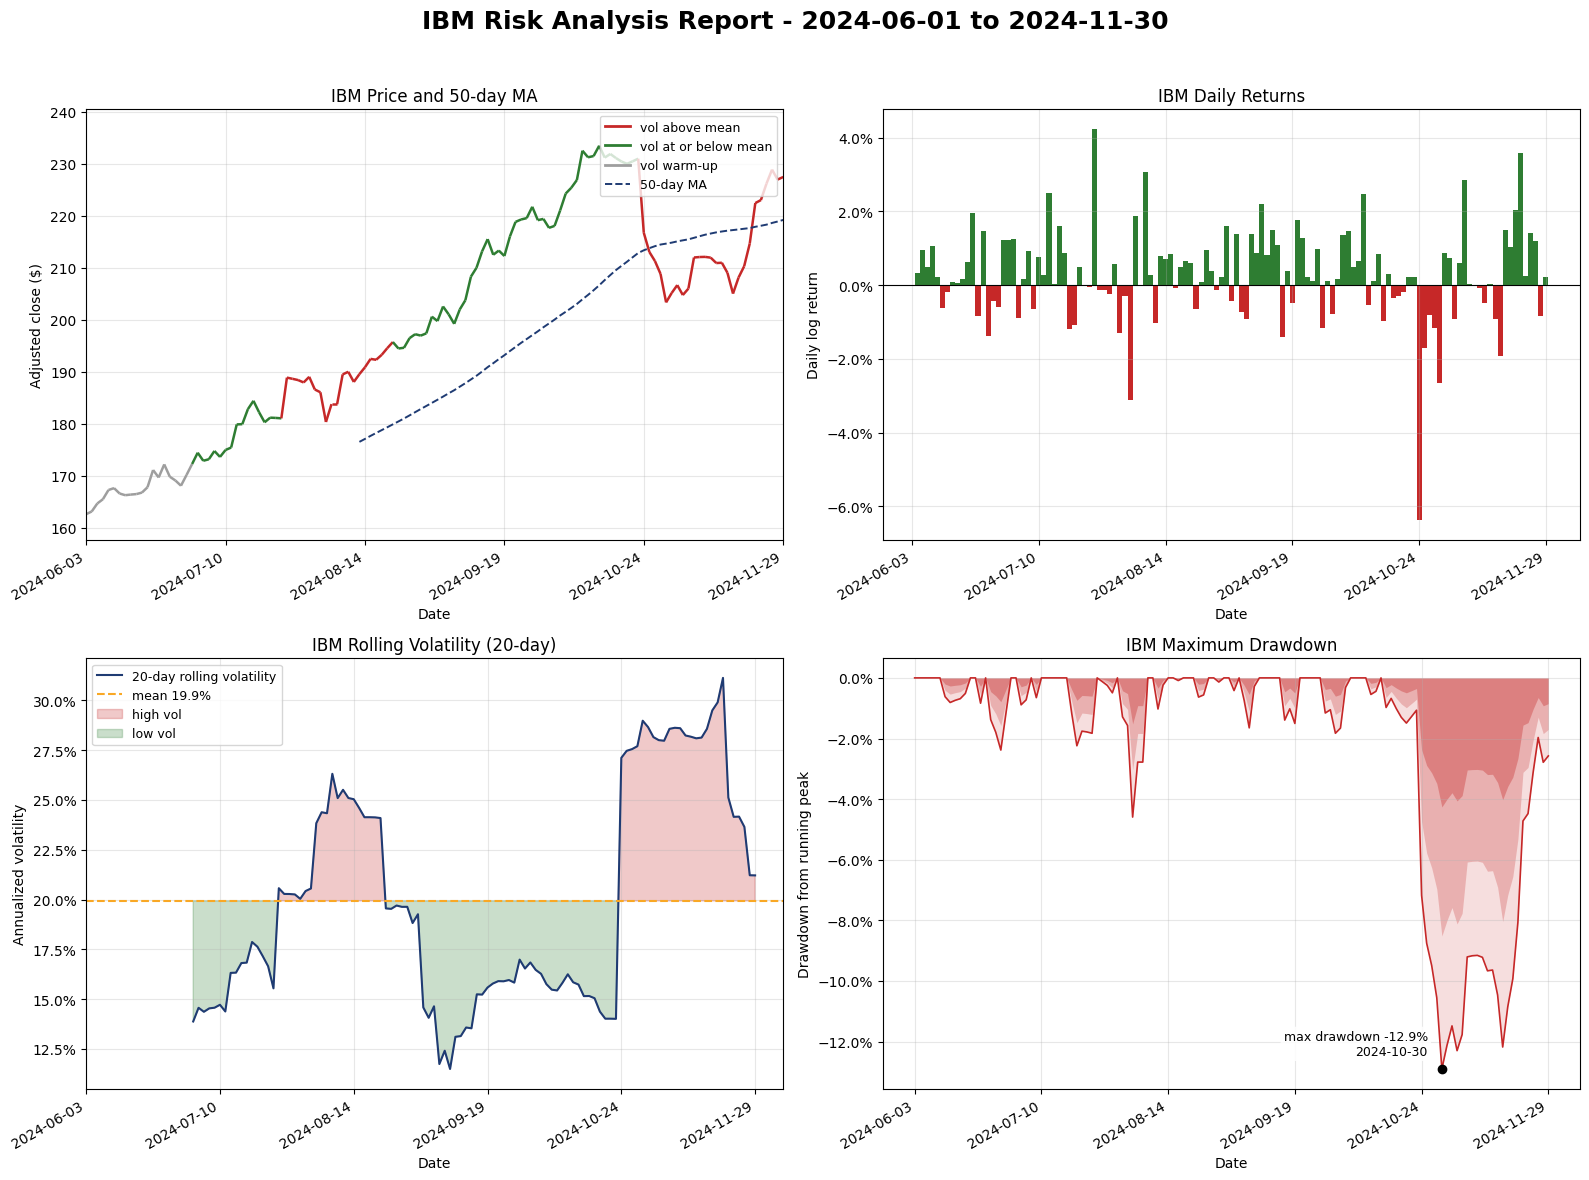

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
x = np.arange(len(adj))

ax = axes[0, 0]
plot_price_by_volatility(ax, adj, rolling_vol, mean_vol, moving_avg)
ax.set_title(f"{ticker} Price and {MA_WINDOW}-day MA")
ax.set_ylabel("Adjusted close ($)")

ax = axes[0, 1]
has_return = log_returns.notna().to_numpy()   # the first day has no return: no bar rather than a zero bar
returns = log_returns.to_numpy()[has_return]
ax.bar(x[has_return], returns, color=np.where(returns >= 0, COLORS["up"], COLORS["down"]), width=1.0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Daily Returns")
ax.set_ylabel("Daily log return")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax = axes[1, 0]
vol = rolling_vol.to_numpy()
ax.plot(x, vol, color=COLORS["line"], linewidth=1.5, label="20-day rolling volatility")
ax.axhline(mean_vol, color=COLORS["accent"], linewidth=1.5, linestyle="--", label=f"mean {mean_vol:.1%}")
ax.fill_between(x, vol, mean_vol, where=vol > mean_vol, color=COLORS["down"], alpha=0.25, interpolate=True, label="high vol")
ax.fill_between(x, vol, mean_vol, where=vol <= mean_vol, color=COLORS["up"], alpha=0.25, interpolate=True, label="low vol")
ax.set_title(f"{ticker} Rolling Volatility ({VOL_WINDOW}-day)")
ax.set_ylabel("Annualized volatility")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="best", fontsize=9)

ax = axes[1, 1]
dd = drawdown.to_numpy()
for alpha, scale in [(0.15, 1.0), (0.25, 0.66), (0.35, 0.33)]:   # layered fills for a red gradient
    ax.fill_between(x, dd * scale, 0, color=COLORS["down"], alpha=alpha, linewidth=0)
ax.plot(x, dd, color=COLORS["down"], linewidth=1.2)
worst = int(np.nanargmin(dd))
on_right = worst > len(dd) / 2   # put the label on the side with room, so it stays inside the chart
ax.scatter([worst], [dd[worst]], color="black", zorder=5)
ax.annotate(f"max drawdown {dd[worst]:.1%}\n{adj.index[worst].date()}", (worst, dd[worst]),
            textcoords="offset points", xytext=(-10, 8) if on_right else (10, 8),
            ha="right" if on_right else "left", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.85))
ax.set_title(f"{ticker} Maximum Drawdown")
ax.set_ylabel("Drawdown from running peak")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    set_date_ticks(ax, adj.index)
    ax.set_xlabel("Date")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Summary statistics

In [10]:
def summary_statistics(adj: pd.Series, log_returns: pd.Series, drawdown: pd.Series) -> dict[str, float]:
    """Whole-period statistics as fractions (NaN when undefined)."""
    r = log_returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        "Total Return": adj.iloc[-1] / adj.iloc[0] - 1,
        "Annualized Return": float(np.exp(r.sum() * TRADING_DAYS / n) - 1) if n else float("nan"),
        "Annualized Volatility": float(r.std() * np.sqrt(TRADING_DAYS)) if n > 1 else float("nan"),
        "Sharpe Ratio": calculate_sharpe_ratio(log_returns),
        "Maximum Drawdown": float(drawdown.min()),
        "Best Day": float(r.max()) if n else float("nan"),
        "Worst Day": float(r.min()) if n else float("nan"),
        "Positive Days": len(up) / n if n else float("nan"),
        "Average Up Day": float(up.mean()) if len(up) else float("nan"),
        "Average Down Day": float(down.mean()) if len(down) else float("nan"),
    }


def format_metric(name: str, value: float) -> str:
    """Display format: signed percentages, plain number for Sharpe, N/A when undefined."""
    if value is None or not np.isfinite(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name == "Annualized Volatility":
        return f"{value:.2%}"
    if name == "Positive Days":
        return f"{value:.1%}"
    return f"{value:+.2%}"

In [11]:
stats = summary_statistics(adj, log_returns, drawdown)
summary_table = pd.DataFrame({"Metric": list(stats), "Value": [format_metric(k, v) for k, v in stats.items()]})
print(summary_table.to_string(index=False))

               Metric   Value
         Total Return +39.88%
    Annualized Return +96.73%
Annualized Volatility  20.42%
         Sharpe Ratio    3.22
     Maximum Drawdown -12.90%
             Best Day  +4.24%
            Worst Day  -6.37%
        Positive Days   63.2%
       Average Up Day  +0.95%
     Average Down Day  -0.92%


## Outputs for the portfolio summary

Named values recorded with scrapbook, so the batch script reads exactly these numbers from each successful report (fractions, not formatted strings).

In [12]:
def clean_number(value: float) -> float | None:
    """A finite metric as a plain float; None for an undefined one (NaN would not be valid JSON)."""
    return float(value) if np.isfinite(value) else None

sb.glue("ticker", ticker)
sb.glue("first_date", str(first_obs))
sb.glue("last_date", str(last_obs))
sb.glue("n_days", int(len(prices)))
sb.glue("avg_daily_return", clean_number(log_returns.mean()))
sb.glue("avg_volatility", clean_number(mean_vol))
sb.glue("max_drawdown", clean_number(drawdown.min()))
sb.glue("sharpe_ratio", clean_number(sharpe))
sb.glue("total_return", clean_number(stats["Total Return"]))